# HR Analytics: Employee Experience, Performance & Training

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn  

This notebook explores employee status, performance ratings, employee survey scores, and training outcomes/costs. The source CSV is shared in anonymized form in `data/`.

## 1. Business questions
- What is the distribution of active and terminated employee records?
- How are performance scores distributed?
- Which departments contribute the most records?
- What do engagement, satisfaction and work-life balance scores look like?
- How are training outcomes and costs distributed?

**Scope note:** This dataset does not contain exit reasons or a labelled attrition target suitable for causal explanation or prediction. The project therefore reports descriptive HR insights, not an attrition prediction model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = 'data/hr_analytics_anonymized.csv'
df = pd.read_csv(DATA_PATH)
df.head()

,Record ID,Title,BusinessUnit,EmployeeStatus,EmployeeType,PayZone,EmployeeClassificationType,DepartmentType,Division,Performance Score,Current Employee Rating,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Program Name,Training Type,Training Outcome,Training Duration(Days),Training Cost,Age
0,EMP0001,Production Technician I,CCDR,Active,Contract,Zone C,Temporary,Production,Finance & Accounting,Fully Meets,4,1,2,3,Leadership Development,Internal,Failed,2,606.11,50
1,EMP0002,Production Technician I,EW,Active,Contract,Zone A,Part-Time,Production,Aerial,Fully Meets,3,2,1,5,Customer Service,External,Incomplete,4,673.02,58
2,EMP0003,Area Sales Manager,PL,Active,Full-Time,Zone B,Part-Time,Sales,General - Sga,Fully Meets,4,1,2,1,Leadership Development,External,Failed,2,413.28,27
3,EMP0004,Area Sales Manager,CCDR,Active,Contract,Zone A,Full-Time,Sales,Finance & Accounting,Fully Meets,2,5,5,4,Project Management,External,Completed,3,663.78,23
4,EMP0005,Area Sales Manager,TNS,Active,Contract,Zone A,Temporary,Sales,General - Con,Fully Meets,3,2,5,3,Technical Skills,External,Failed,5,399.03,50


## 2. Data overview and quality checks

In [2]:
print('Shape:', df.shape)
display(df.info())
display(df.describe(include='all').T)

Shape: (2845, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2845 entries, 0 to 2844
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Record ID                   2845 non-null   object 
 1   Title                       2845 non-null   object 
 2   BusinessUnit                2845 non-null   object 
 3   EmployeeStatus              2845 non-null   object 
 4   EmployeeType                2845 non-null   object 
 5   PayZone                     2845 non-null   object 
 6   EmployeeClassificationType  2845 non-null   object 
 7   DepartmentType              2845 non-null   object 
 8   Division                    2845 non-null   object 
 9   Performance Score           2845 non-null   object 
 10  Current Employee Rating     2845 non-null   int64  
 11  Engagement Score            2845 non-null   int64  
 12  Satisfaction Score          2845 non-null   int64  
 13  Work-Life Balan

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record ID,2845,2845,EMP0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Title,2845,31,Production Technician I,1241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessUnit,2845,10,NEL,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeStatus,2845,2,Active,2458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeType,2845,3,Full-Time,997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayZone,2845,3,Zone A,1013,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeClassificationType,2845,3,Temporary,980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DepartmentType,2845,6,Production,1910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Division,2845,25,Field Operations,747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Performance Score,2845,4,Fully Meets,2251,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print('Duplicate rows:', df.duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])
print('Unique record IDs:', df['Record ID'].nunique())

Duplicate rows: 0


Series([], dtype: int64)

Unique record IDs: 2845


## 3. Employee status and performance

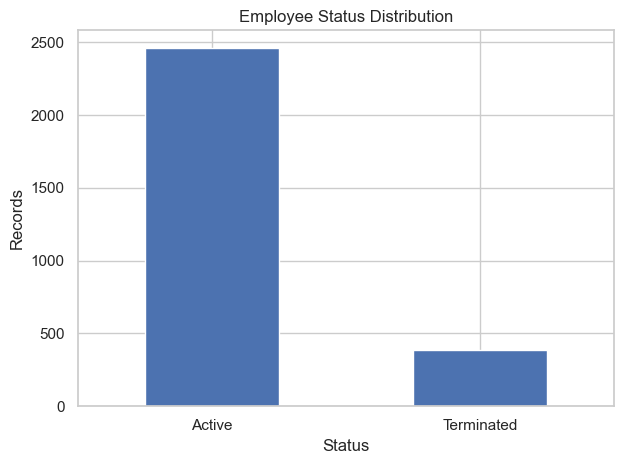

EmployeeStatus
Active        86.4
Terminated    13.6
Name: count, dtype: float64


In [4]:
status_counts = df['EmployeeStatus'].value_counts()
ax = status_counts.plot(kind='bar', title='Employee Status Distribution', ylabel='Records', xlabel='Status')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print((status_counts / len(df) * 100).round(1))

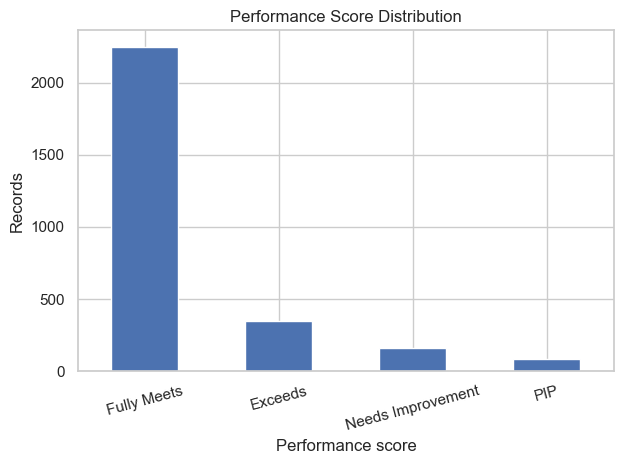

Performance Score
Fully Meets          79.1
Exceeds              12.2
Needs Improvement     5.7
PIP                   3.0
Name: count, dtype: float64


In [5]:
perf_counts = df['Performance Score'].value_counts()
perf_counts.plot(kind='bar', title='Performance Score Distribution', ylabel='Records', xlabel='Performance score')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print((perf_counts / len(df) * 100).round(1))

## 4. Department-level view

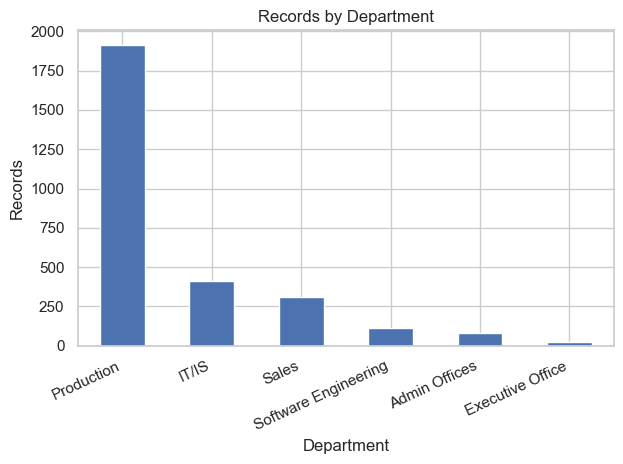

,records,avg_rating,avg_engagement,avg_satisfaction,avg_work_life_balance,avg_training_cost
DepartmentType,,,,,,
Production,1910,2.99,2.91,3.03,2.97,560.35
IT/IS,409,2.97,3.02,3.01,2.98,563.32
Sales,311,2.92,2.98,3.14,3.03,540.25
Software Engineering,112,2.90,2.96,3.10,2.99,592.12
Admin Offices,79,3.03,2.95,2.51,3.20,532.92
Executive Office,24,2.79,3.38,3.08,3.29,585.47


In [6]:
dept_counts = df['DepartmentType'].value_counts()
dept_counts.plot(kind='bar', title='Records by Department', ylabel='Records', xlabel='Department')
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()
display(df.groupby('DepartmentType').agg(
    records=('Record ID','count'),
    avg_rating=('Current Employee Rating','mean'),
    avg_engagement=('Engagement Score','mean'),
    avg_satisfaction=('Satisfaction Score','mean'),
    avg_work_life_balance=('Work-Life Balance Score','mean'),
    avg_training_cost=('Training Cost','mean')
).round(2).sort_values('records', ascending=False))

## 5. Employee survey scores

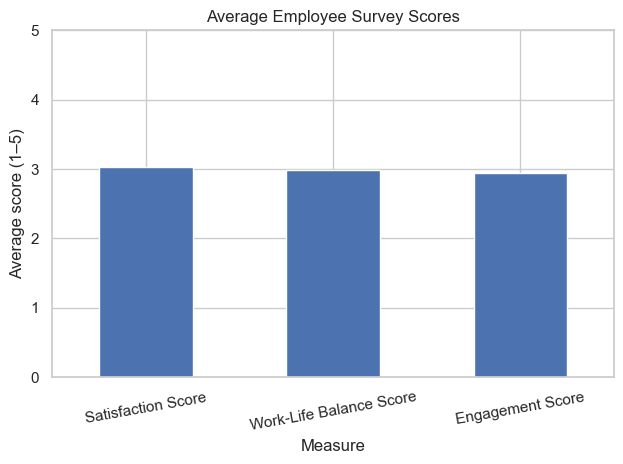

,Engagement Score,Satisfaction Score,Work-Life Balance Score
count,2845.00,2845.00,2845.00
mean,2.94,3.03,2.99
std,1.44,1.41,1.41
min,1.00,1.00,1.00
25%,2.00,2.00,2.00
50%,3.00,3.00,3.00
75%,4.00,4.00,4.00
max,5.00,5.00,5.00


In [7]:
survey_cols = ['Engagement Score','Satisfaction Score','Work-Life Balance Score']
score_means = df[survey_cols].mean().sort_values(ascending=False)
score_means.plot(kind='bar', title='Average Employee Survey Scores', ylabel='Average score (1–5)', xlabel='Measure')
plt.xticks(rotation=10); plt.ylim(0,5); plt.tight_layout(); plt.show()
display(df[survey_cols].describe().round(2))

## 6. Training outcomes and investment

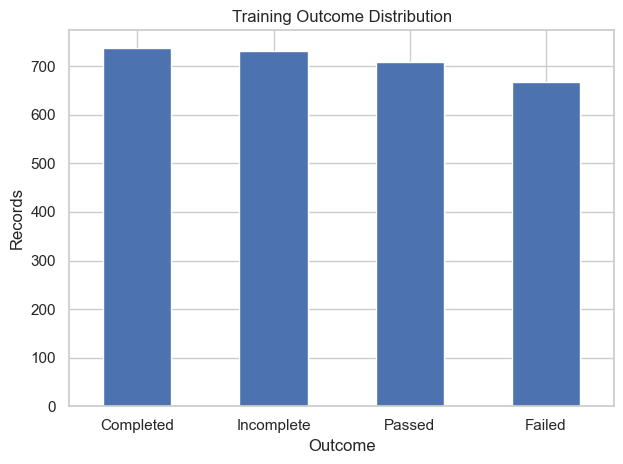

Training Outcome
Completed     25.9
Incomplete    25.7
Passed        24.9
Failed        23.5
Name: count, dtype: float64


In [8]:
outcome_counts = df['Training Outcome'].value_counts()
outcome_counts.plot(kind='bar', title='Training Outcome Distribution', ylabel='Records', xlabel='Outcome')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print((outcome_counts / len(df) * 100).round(1))

In [9]:
training_summary = df.groupby('Training Outcome').agg(
    records=('Record ID','count'),
    avg_duration_days=('Training Duration(Days)','mean'),
    avg_training_cost=('Training Cost','mean'),
    total_training_cost=('Training Cost','sum')
).round(2)
display(training_summary.sort_values('records', ascending=False))

,records,avg_duration_days,avg_training_cost,total_training_cost
Training Outcome,,,,
Completed,737,2.96,565.03,416427.62
Incomplete,731,2.92,552.88,404152.34
Passed,709,3.02,561.93,398411.35
Failed,668,3.00,557.12,372157.32


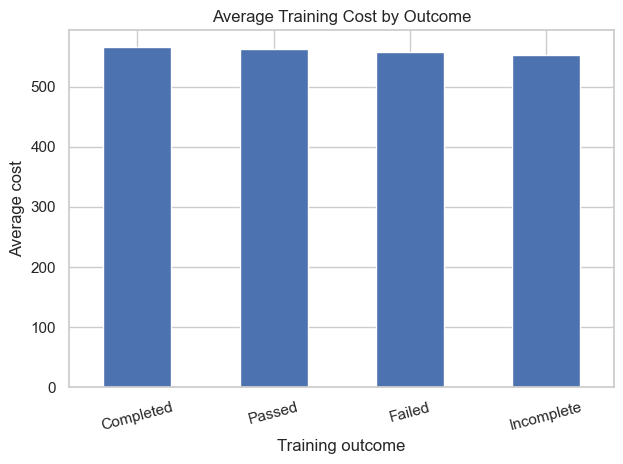

Total recorded training cost: 1591148.63


In [10]:
cost_by_outcome = df.groupby('Training Outcome')['Training Cost'].mean().sort_values(ascending=False)
cost_by_outcome.plot(kind='bar', title='Average Training Cost by Outcome', ylabel='Average cost', xlabel='Training outcome')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print('Total recorded training cost:', round(df['Training Cost'].sum(), 2))

## 7. Correlation check

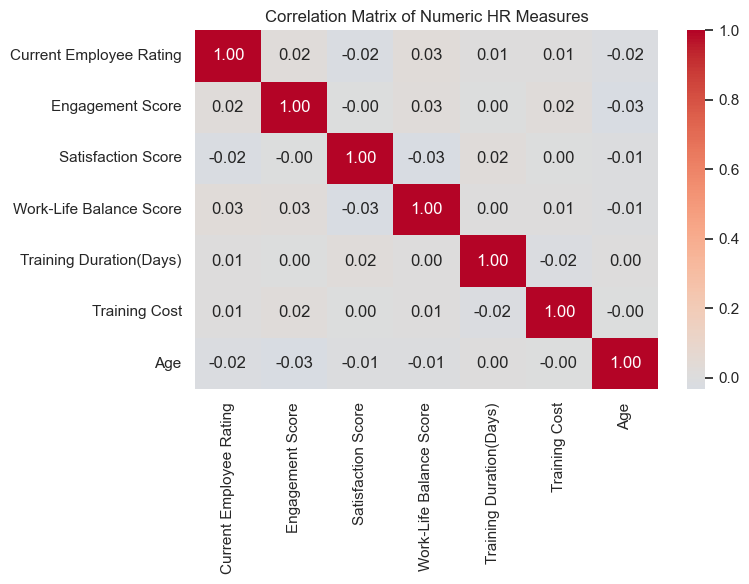

In [11]:
numeric_cols = ['Current Employee Rating','Engagement Score','Satisfaction Score',
                'Work-Life Balance Score','Training Duration(Days)','Training Cost','Age']
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Matrix of Numeric HR Measures')
plt.tight_layout(); plt.show()

## 8. Key findings (descriptive)
- The dataset contains **2,845 records and 28 source columns** before anonymization.
- Employee status: **2,458 Active (86.4%)** and **387 Terminated (13.6%)**.
- **Fully Meets** is the most common performance category (**2,251 records; 79.1%**).
- Production is the largest department group (**1,910 records**).
- Average scores: engagement **2.94/5**, satisfaction **3.03/5**, work-life balance **2.99/5**.
- Training outcomes are spread across Completed (**737**), Incomplete (**731**), Passed (**709**) and Failed (**668**).
- Total recorded training cost is **1,591,148.63** (currency/unit not specified in the source, so no currency symbol is assumed).

These are descriptive summaries of the provided dataset. They do not establish why employees leave or whether training causes changes in performance.

## 9. Recommendations and limitations
**Recommended follow-up:** review training completion barriers; compare survey scores by department; validate the meaning and scale of employee ratings with the data owner; and obtain exit reasons/tenure history before conducting attrition root-cause analysis.

**Limitations:** source data definitions and currency are not supplied; survey scales are assumed to be 1–5 based on observed values; the dataset contains employee-related fields and has therefore been anonymized for public sharing. Results should be interpreted as an exploratory portfolio analysis, not an audited HR report.

## 10. Reproducibility
Run the notebook from the project root so the relative CSV path resolves. Install dependencies with `pip install -r requirements.txt`.